## 1. Setup

In [1]:
# ── Imports, device, reproducibility helpers ─────────────────────────────────────────────
import copy
import glob
import json
import math
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Mixed precision: the T4 has fp16 Tensor Cores (no bf16/TF32), so autocast to float16 gives
# a large speed-up for the Linear/Conv layers. The FFT-based Auto-Correlation is forced back
# to float32 inside the layer (cuFFT in half precision is restricted and less accurate).
USE_AMP = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
print("torch", torch.__version__, "| device:",
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU", "| AMP:", USE_AMP)


def set_seed(seed):
    """Seed every RNG we use (Python, NumPy, PyTorch CPU + GPU)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def find_file(name):
    """Locate a data file on Kaggle (/kaggle/input), Colab (/content) or locally."""
    for pattern in (f"{name}", f"Data/{name}", f"**/{name}",
                    f"/kaggle/input/**/{name}", f"/content/**/{name}"):
        hits = sorted(glob.glob(pattern, recursive=True))
        if hits:
            return Path(hits[0])
    raise FileNotFoundError(f"{name} not found - add the Data folder as an input.")

torch 2.11.0+cu128 | device: Tesla T4 | AMP: True


In [2]:
# ── Load the three files and verify the properties §2.2 says we may rely on ──────────────
train_df = pd.read_csv(find_file("student_train.csv"))
test_df = pd.read_csv(find_file("student_test.csv"))
ext_df = pd.read_csv(find_file("optional_external_data.csv"))

N_TRAIN = len(train_df)                 # 43,656 observed values
N_TOTAL = len(ext_df)                   # 43,824 = observed + 168 hidden
HORIZON = 168                           # pred_len fixed by §2.4(2)
assert N_TRAIN == 43_656 and N_TOTAL == 43_824 and len(test_df) == HORIZON
assert (np.diff(train_df.time_idx) == 1).all() and train_df.time_idx.iloc[0] == 1  # uniform grid
assert train_df.value.notna().all()                                               # no gaps
assert test_df.time_idx.iloc[0] == 43_657 and test_df.time_idx.iloc[-1] == 43_824
assert (ext_df.time_idx.values == np.arange(1, N_TOTAL + 1)).all()

y_raw = train_df.value.to_numpy(dtype=np.float64)        # target, position p <-> time_idx p+1
FEATURES = [c for c in ext_df.columns if c.startswith("feature_")]
X_ext = ext_df[FEATURES].to_numpy(dtype=np.float64)       # [43824, 10], covers the horizon too
BINARY = [f for f in FEATURES if set(np.unique(ext_df[f])) <= {0, 1}]
CONTINUOUS = [f for f in FEATURES if f not in BINARY]
print(f"target: n={N_TRAIN}, min={y_raw.min():.0f}, median={np.median(y_raw):.0f}, "
      f"mean={y_raw.mean():.1f}, max={y_raw.max():.0f}, zeros={int((y_raw == 0).sum())}")
print("continuous features:", CONTINUOUS)
print("binary features:", BINARY, "| mutually exclusive at every step:",
      bool((ext_df[BINARY].sum(1) == 1).all()))

target: n=43656, min=0, median=73, mean=98.2, max=994, zeros=2
continuous features: ['feature_A', 'feature_B', 'feature_C', 'feature_D', 'feature_E', 'feature_F']
binary features: ['feature_G', 'feature_H', 'feature_I', 'feature_J'] | mutually exclusive at every step: True


## 2. Exploratory analysis

**Heavy tails.** §2.2 warns that the level can change by an order of magnitude within one
horizon. A `log1p` transform compresses those spikes. Whether it helps the *raw-scale* RMSE
used for ranking is an empirical question, so it's ablated in §9 rather than assumed.

**Periodicity without timestamps (Q2.8).** The sampling interval is hidden, so the periods
are recovered from the data:
* the **autocorrelation function** (Lecture 2 §5: for a wide-sense stationary process it
  depends only on the delay), whose local maxima sit at the period and its multiples;
* the **periodogram** |FFT|², whose peaks are the dominant frequencies.

Only the training region is used, so nothing about the hidden block leaks in.

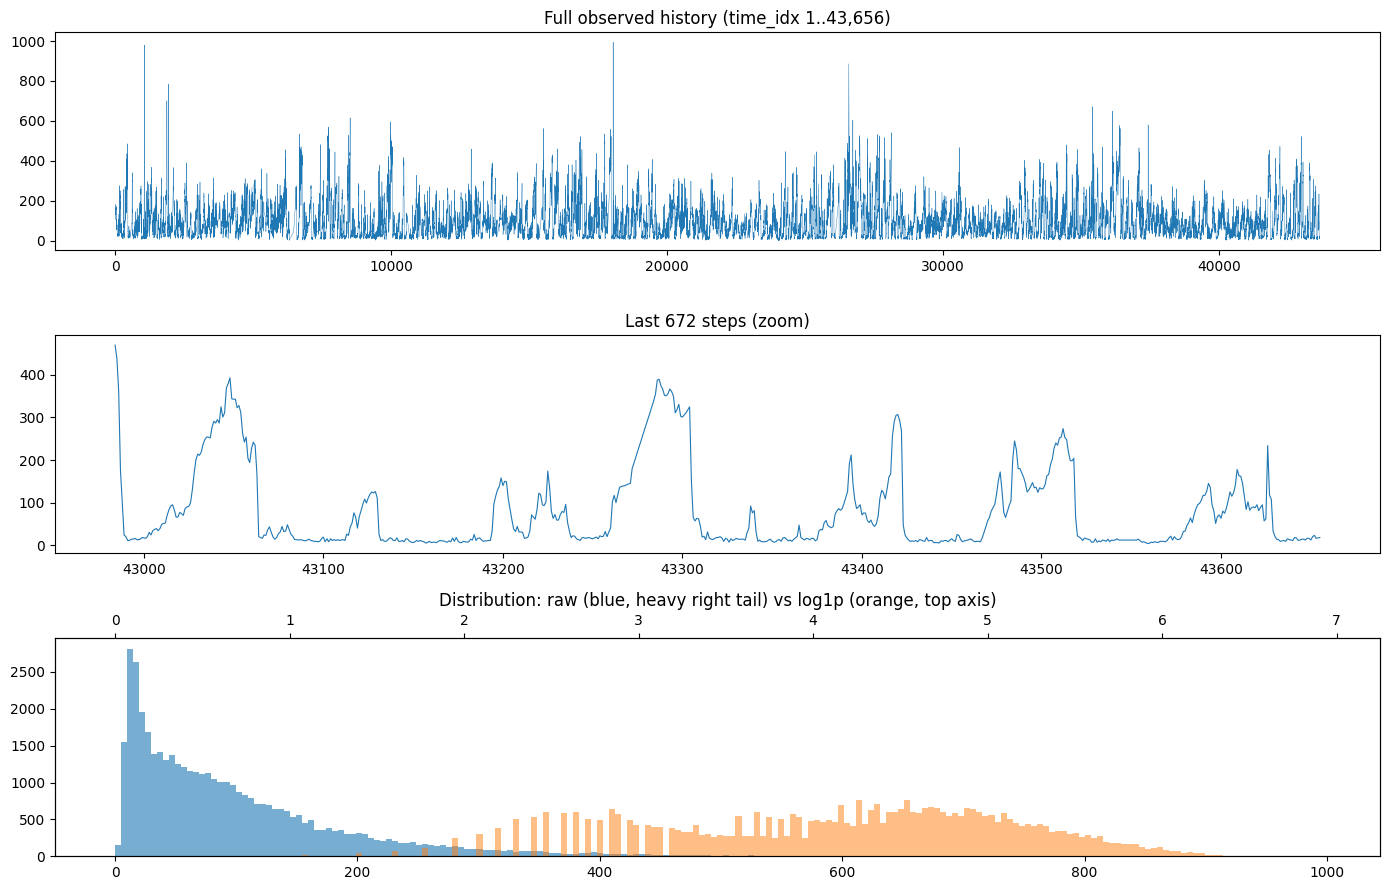

quantiles 50/90/99/99.9 %: [ 73. 218. 418. 571.] | skewness: 1.83


In [3]:
# ── Look at the series: level, spikes, distribution ─────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 9))
axes[0].plot(y_raw, lw=0.3)
axes[0].set_title("Full observed history (time_idx 1..43,656)")
axes[1].plot(np.arange(N_TRAIN - 24 * 7 * 4, N_TRAIN), y_raw[-24 * 7 * 4:], lw=0.8)
axes[1].set_title("Last 672 steps (zoom)")
axes[2].hist(y_raw, bins=200, alpha=0.6, label="raw")
ax2 = axes[2].twiny()
ax2.hist(np.log1p(y_raw), bins=200, color="C1", alpha=0.5, label="log1p")
axes[2].set_title("Distribution: raw (blue, heavy right tail) vs log1p (orange, top axis)")
plt.tight_layout()
plt.savefig(OUT / "eda_series.pdf")
plt.show()
q = np.quantile(y_raw, [0.5, 0.9, 0.99, 0.999])
print("quantiles 50/90/99/99.9 %:", q.round(1), "| skewness:",
      round(float(pd.Series(y_raw).skew()), 2))

dominant periods (samples): [270, 377, 24] | short period used for windows: 24
ACF local maxima (first 10 lags): [72, 95, 121, 143, 169, 192, 216, 239, 264, 287]


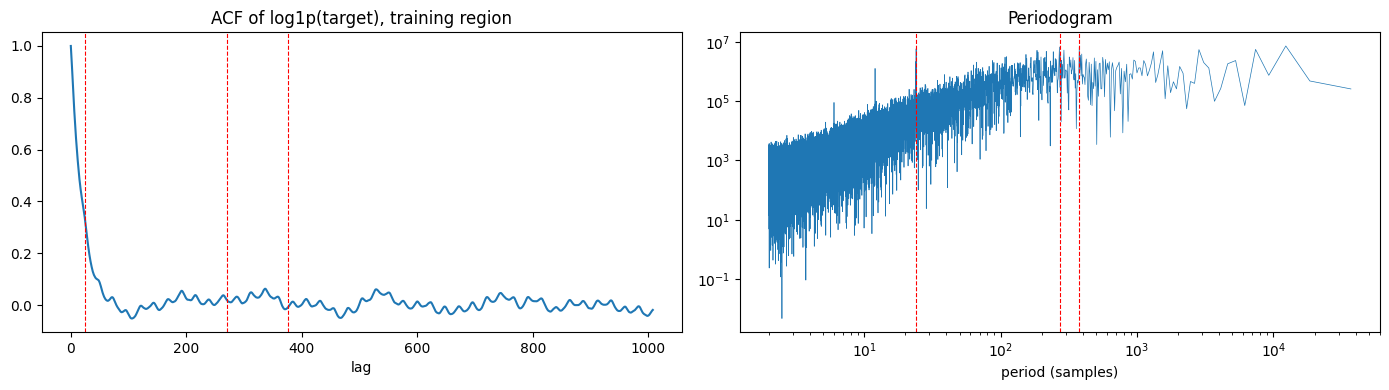

In [4]:
# ── Periodicity discovery (ACF + periodogram) on the TRAINING region only ────────────────
# The cut-off below must equal TRAIN_END defined in §4 (asserted there).
EDA_END = N_TRAIN - 40 * HORIZON
x = np.log1p(y_raw[:EDA_END])
x = x - x.mean()


def acf(series, max_lag):
    """Autocorrelation for lags 0..max_lag via FFT (zero-padded to avoid circular wrap)."""
    spectrum = np.fft.rfft(series, n=2 * len(series))
    ac = np.fft.irfft(spectrum * np.conj(spectrum))[: max_lag + 1]
    return ac / ac[0]


ac = acf(x, 24 * 7 * 6)
power = np.abs(np.fft.rfft(x)) ** 2
freq = np.fft.rfftfreq(len(x))
valid = (freq > 0) & (1 / np.maximum(freq, 1e-12) <= len(x) / 4)   # >= 4 cycles in the data
order = np.argsort(power * valid)[::-1]

# Keep the strongest periods, skipping near-duplicates and harmonics (P/2, P/3, ...) of a
# period that is already accepted.
PERIODS = []
for i in order[:400]:
    p = 1 / freq[i]
    if p < 3:
        continue
    near = any(abs(p - a / k) / (a / k) < 0.05 for a in PERIODS for k in range(1, 7))
    if not near:
        PERIODS.append(float(p))
    if len(PERIODS) == 3:
        break
PERIODS = [int(round(p)) for p in PERIODS]
SHORT_PERIOD = min(p for p in PERIODS if p <= 336) if any(p <= 336 for p in PERIODS) else 24
print("dominant periods (samples):", PERIODS, "| short period used for windows:", SHORT_PERIOD)

lag_peaks = [l for l in range(2, len(ac) - 1) if ac[l] > ac[l - 1] and ac[l] >= ac[l + 1]]
print("ACF local maxima (first 10 lags):", lag_peaks[:10])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(ac)
for p in PERIODS:
    if p < len(ac):
        axes[0].axvline(p, color="r", ls="--", lw=0.8)
axes[0].set(title="ACF of log1p(target), training region", xlabel="lag")
axes[1].loglog(1 / freq[1:], power[1:], lw=0.5)
for p in PERIODS:
    axes[1].axvline(p, color="r", ls="--", lw=0.8)
axes[1].set(title="Periodogram", xlabel="period (samples)")
plt.tight_layout()
plt.savefig(OUT / "eda_periodicity.pdf")
plt.show()

## 3. Optional external file: what might it carry?

§2.3: the file covers the 168 hidden steps as well, and using it is allowed. Two questions
need settling **experimentally** (§9.2):

1. Does it carry signal about the target at all?
2. **When is each part available?** The *past* part (up to the forecast origin) can only
   describe the context. The *future* part (inside the horizon) describes conditions while
   the target unfolds. In an encoder–decoder (Q2.7), the past part belongs in the
   **encoder**. The future part can only enter the **decoder**, whose positions are the
   horizon.

The cell below just measures correlations on the training region. It's a hint, not a
decision.

In [5]:
# ── Correlation of each covariate with the (log) target, at lag 0 and as a 24-step lead ──
corr_rows = []
log_y = np.log1p(y_raw[:EDA_END])
for j, name in enumerate(FEATURES):
    f = X_ext[:EDA_END, j]
    row = {"feature": name, "type": "binary" if name in BINARY else "continuous",
           "corr(f_t, y_t)": np.corrcoef(f, log_y)[0, 1],
           # does the covariate a day ahead relate to the target change over that day?
           "corr(f_t+24 - f_t, y_t+24 - y_t)": np.corrcoef(
               f[24:] - f[:-24], log_y[24:] - log_y[:-24])[0, 1]}
    corr_rows.append(row)
corr_table = pd.DataFrame(corr_rows).round(3)
corr_table.to_csv(OUT / "covariate_correlations.csv", index=False)
display(corr_table)

,feature,type,"corr(f_t, y_t)","corr(f_t+24 - f_t, y_t+24 - y_t)"
0,feature_A,continuous,0.321,0.681
1,feature_B,continuous,0.033,-0.031
2,feature_C,continuous,-0.174,-0.434
3,feature_D,continuous,-0.358,-0.296
4,feature_E,continuous,0.034,0.030
5,feature_F,continuous,-0.052,-0.061
6,feature_G,binary,-0.065,-0.077
7,feature_H,binary,-0.352,-0.287
8,feature_I,binary,0.232,0.201
9,feature_J,binary,0.189,0.155


## 4. Chronological validation protocol

The leaderboard gives 5 submissions on **one** 168-step block, so it can't be used to tune
(§2.5). Instead the observed history is split **in time order** (no shuffling, no future
information):

| Region | Targets | Use |
|---|---|---|
| train | `[0, TRAIN_END)` | fit weights, scaling statistics, EDA |
| early-stop | `[TRAIN_END, SEL_START)` (20 × 168 steps) | choose the epoch (early stopping) |
| **selection** | `[SEL_START, 43,656)` (**20 non-overlapping 168-step blocks**) | compare designs; never used for fitting |

Each selection block is a rolling-origin forecast exactly like the leaderboard task:
context ends at the block start, predict the next 168. Averaging over 20 blocks × several
seeds is far more trustworthy than one leaderboard score.

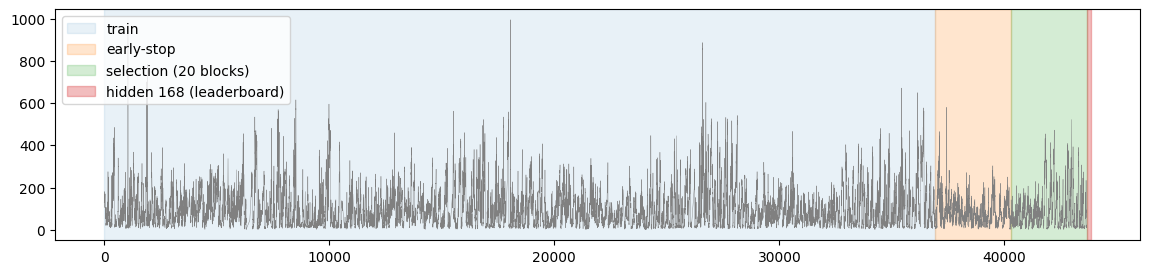

train targets < 36936, early-stop [36936, 40296), selection [40296, 43656), forecast [43656, 43824)


In [6]:
# ── Region boundaries (0-based positions into y_raw) ─────────────────────────────────────
N_BLOCKS = 20
SEL_START = N_TRAIN - N_BLOCKS * HORIZON          # 40,296
TRAIN_END = SEL_START - N_BLOCKS * HORIZON        # 36,936
assert TRAIN_END == EDA_END                        # EDA used only the training region
SEL_ORIGINS = np.arange(SEL_START, N_TRAIN - HORIZON + 1, HORIZON)   # 20 block starts
assert len(SEL_ORIGINS) == N_BLOCKS and SEL_ORIGINS[-1] + HORIZON == N_TRAIN

fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(y_raw, lw=0.3, color="gray")
ax.axvspan(0, TRAIN_END, alpha=0.1, color="C0", label="train")
ax.axvspan(TRAIN_END, SEL_START, alpha=0.2, color="C1", label="early-stop")
ax.axvspan(SEL_START, N_TRAIN, alpha=0.2, color="C2", label="selection (20 blocks)")
ax.axvspan(N_TRAIN, N_TOTAL, alpha=0.3, color="C3", label="hidden 168 (leaderboard)")
ax.legend(loc="upper left")
plt.savefig(OUT / "split.pdf", bbox_inches="tight")
plt.show()
print(f"train targets < {TRAIN_END}, early-stop [{TRAIN_END}, {SEL_START}), "
      f"selection [{SEL_START}, {N_TRAIN}), forecast [{N_TRAIN}, {N_TOTAL})")

## 5. Configuration, preprocessing and windows

* **Target transform** (`"none"` or `"log1p"`), then a z-score whose mean and std come from
  the *training region only*. Predictions are inverted and clipped at 0, since the target
  is non-negative.
* **Marks (time/covariate features)** are added to the token embedding (Lecture 5 §2:
  token = value + position + time features):
  * *phase features* `sin/cos(2π·t/P)` for each discovered period P. They depend only on
    `time_idx`, so they're known for the horizon too. This is the substitute for the missing
    calendar (Q2.8).
  * *optional covariates* (continuous ones z-scored on the training region, binary ones
    kept as 0/1) in one of three modes:
    `none`; `past` (encoder + decoder label part only, horizon positions zeroed);
    `future` (also across the 168-step horizon, which §2.3 allows).
* **Windows**: encoder sees `seq_len` steps before the origin. The decoder covers
  `label_len` known steps plus the 168 to forecast (the Autoformer decoder layout).

In [7]:
# ── All hyper-parameters in one place (the experiments in §9 override a few of them) ──────
BASE = dict(
    seq_len=2 * 168,         # encoder context: 2 x the 168-step horizon
    label_len=168,           # decoder "start token" length (known history fed to decoder)
    pred_len=HORIZON,        # fixed by §2.4(2)
    transform="log1p",       # "none" | "log1p"
    phase=True,              # sin/cos phase features of the discovered periods
    external="none",         # "none" | "past" | "future" use of optional_external_data.csv
    d_model=32, n_heads=4, e_layers=2, d_layers=1, d_ff=64,
    moving_avg=SHORT_PERIOD + 1 if SHORT_PERIOD % 2 == 0 else SHORT_PERIOD,  # odd, ~1 period
    factor=3,                # top_k = int(factor * ln L) delays (Q2.4)
    dropout=0.05,
    lr=1e-3, weight_decay=1e-4, batch_size=128, max_epochs=10, patience=3,
    train_stride=1,          # every training origin is used
    # v2 switches -- the defaults reproduce v1 exactly, so v1 runs stay comparable
    features="basic",        # "basic" | "engineered" covariates (when external != "none")
    mark_mlp=False,          # non-linear (MLP) mark embedding instead of a linear one
    exo_head=False,          # direct covariate -> target head added to the Autoformer output
    schedule="halve",        # "halve" (Autoformer type1) | "cosine"
    sched_epochs=None,       # cosine length; None = max_epochs (kept fixed when refitting)
)
print(json.dumps(BASE, indent=1))

{
 "seq_len": 336,
 "label_len": 168,
 "pred_len": 168,
 "transform": "log1p",
 "phase": true,
 "external": "none",
 "d_model": 32,
 "n_heads": 4,
 "e_layers": 2,
 "d_layers": 1,
 "d_ff": 64,
 "moving_avg": 25,
 "factor": 3,
 "dropout": 0.05,
 "lr": 0.001,
 "weight_decay": 0.0001,
 "batch_size": 128,
 "max_epochs": 10,
 "patience": 3,
 "train_stride": 1,
 "features": "basic",
 "mark_mlp": false,
 "exo_head": false,
 "schedule": "halve",
 "sched_epochs": null
}


In [8]:
# ── Preprocessing: transform + scaling (fit on training rows only) + feature matrix ───────
def forward_transform(values, cfg):
    return np.log1p(values) if cfg["transform"] == "log1p" else values.copy()


def inverse_transform(z, stats, cfg):
    """Undo z-score and transform, then clip: the target is non-negative."""
    values = z * stats["std"] + stats["mean"]
    values = np.expm1(values) if cfg["transform"] == "log1p" else values
    return np.clip(values, 0.0, None)


def engineered_covariates():
    """v2: extra covariates derived ONLY from optional_external_data.csv (same clock, known
    over the horizon too). Motivated by §3: 24-step CHANGES of feature_A / feature_C
    correlate with 24-step changes of the target (0.68 / -0.43) far more than their levels."""
    col = {name: X_ext[:, j] for j, name in enumerate(FEATURES)}
    lag = SHORT_PERIOD                                     # discovered daily cycle (24)

    def change(x):                                         # x_t - x_{t-lag} (causal)
        return np.r_[np.zeros(lag), x[lag:] - x[:-lag]]

    def trailing_mean(x):                                  # mean of the last `lag` steps
        return pd.Series(x).rolling(lag, min_periods=1).mean().to_numpy()

    # D, E, F are heavy-tailed, non-negative accumulators -> log1p compresses their tails
    heavy = {n: np.log1p(np.clip(col[n], 0, None)) for n in ("feature_D", "feature_E", "feature_F")}
    out = list(heavy.values())
    out.append(col["feature_A"] - col["feature_B"])        # A and B share range/units
    out += [change(col[n]) for n in ("feature_A", "feature_B", "feature_C")]
    out += [trailing_mean(col[n]) for n in ("feature_A", "feature_C")]
    out.append(trailing_mean(heavy["feature_D"]))
    out += [heavy["feature_D"] * col[b] for b in BINARY]   # accumulator split by binary state
    return out


def prepare(cfg, fit_end):
    """Build every tensor the model needs, using only rows < fit_end for statistics."""
    t = forward_transform(y_raw, cfg)
    stats = {"mean": float(t[:fit_end].mean()), "std": float(t[:fit_end].std())}
    y_t = (t - stats["mean"]) / stats["std"]

    blocks, future_mask_cols = [], []
    time_idx = np.arange(1, N_TOTAL + 1, dtype=np.float64)
    if cfg["phase"]:
        for p in PERIODS:                           # deterministic -> known in the horizon
            blocks += [np.sin(2 * np.pi * time_idx / p), np.cos(2 * np.pi * time_idx / p)]
            future_mask_cols += [False, False]
    if cfg["external"] != "none":
        for j, name in enumerate(FEATURES):
            col = X_ext[:, j]
            if name in CONTINUOUS:                  # z-score with training-region stats only
                col = (col - col[:fit_end].mean()) / (col[:fit_end].std() + 1e-8)
            blocks.append(col)
            future_mask_cols.append(cfg["external"] == "past")   # hide horizon in "past" mode
        if cfg.get("features") == "engineered":    # v2: z-scored on training rows only
            for col in engineered_covariates():
                blocks.append((col - col[:fit_end].mean()) / (col[:fit_end].std() + 1e-8))
                future_mask_cols.append(cfg["external"] == "past")
    if not blocks:                                  # keep a (zero) column so shapes are fixed
        blocks, future_mask_cols = [np.zeros(N_TOTAL)], [False]
    feat = np.stack(blocks, axis=1)                 # [43824, n_mark]

    L, S, H = cfg["seq_len"], cfg["label_len"], cfg["pred_len"]
    dec_off = np.arange(-S, H)                      # decoder positions relative to origin
    mask = np.ones((S + H, feat.shape[1]), dtype=np.float32)
    mask[np.ix_(dec_off >= 0, np.array(future_mask_cols))] = 0.0  # zero unknown future values
    to = lambda a, dtype=torch.float32: torch.as_tensor(a, dtype=dtype, device=DEVICE)
    return dict(y=to(y_t), feat=to(feat), dec_mask=to(mask), stats=stats,
                enc_off=to(np.arange(-L, 0), torch.long), dec_off=to(dec_off, torch.long),
                tgt_off=to(np.arange(H), torch.long), n_mark=feat.shape[1])


def make_batch(origins, D):
    """Gather one batch of windows directly on the GPU (no DataLoader needed: the whole
    series is a few hundred KB, so indexing pre-loaded tensors is the fastest option).
    origin o = position of the FIRST forecast step; context is [o - L, o)."""
    enc_idx = origins[:, None] + D["enc_off"][None]          # [B, L]
    dec_idx = origins[:, None] + D["dec_off"][None]          # [B, S + H]
    x_enc = D["y"][enc_idx].unsqueeze(-1)                     # [B, L, 1]
    mark_enc = D["feat"][enc_idx]                             # [B, L, n_mark]
    mark_dec = D["feat"][dec_idx] * D["dec_mask"]             # [B, S + H, n_mark]
    return x_enc, mark_enc, mark_dec


def targets(origins, D):
    return D["y"][origins[:, None] + D["tgt_off"][None]]      # [B, H]


def origin_range(start, stop, stride, cfg):
    """Origins whose context starts at >= 0 and whose 168 targets lie in [start, stop)."""
    first = max(start, cfg["seq_len"])
    last = stop - cfg["pred_len"] + 1
    if last <= first:                  # no complete target fits (e.g. the refit path)
        return torch.empty(0, dtype=torch.long, device=DEVICE)
    return torch.arange(first, last, stride, device=DEVICE)

## 6. Classical baselines (Lecture 3 §2)

*"The absolute baseline any algorithm you design must be able to beat."* These need no
training and are scored on the same 20 selection blocks:
* **naïve** repeats the last observed value;
* **seasonal naïve** repeats the last full cycle of the discovered short period (and of 168).

In [9]:
# ── Metrics of §2.6 (always on the raw, physical scale) ──────────────────────────────────
def metrics(y_true, y_pred):
    err = y_pred - y_true
    denom = np.abs(y_true) + np.abs(y_pred)
    smape_terms = np.where(denom == 0, 0.0, 2 * np.abs(err) / np.where(denom == 0, 1, denom))
    return {"MAE": float(np.abs(err).mean()), "RMSE": float(np.sqrt((err ** 2).mean())),
            "sMAPE": float(100 * smape_terms.mean())}


TRUTH = np.stack([y_raw[o:o + HORIZON] for o in SEL_ORIGINS])     # [20, 168]


def block_rmse(pred):
    return np.sqrt(((pred - TRUTH) ** 2).mean(axis=1))              # one RMSE per block


def seasonal_naive(o, period):
    last_cycle = y_raw[o - period:o]
    return np.resize(last_cycle, HORIZON)          # repeat the last cycle across 168 steps


baselines = {"naive (last value)": np.stack([np.full(HORIZON, y_raw[o - 1]) for o in SEL_ORIGINS]),
             "mean of last 168": np.stack([np.full(HORIZON, y_raw[o - 168:o].mean())
                                           for o in SEL_ORIGINS])}
for p in sorted({SHORT_PERIOD, 168}):
    baselines[f"seasonal naive (P={p})"] = np.stack([seasonal_naive(o, p) for o in SEL_ORIGINS])
baseline_table = pd.DataFrame([{"model": k, **metrics(TRUTH, v)} for k, v in baselines.items()])
baseline_table.to_csv(OUT / "baselines.csv", index=False)
display(baseline_table.round(3))

,model,MAE,RMSE,sMAPE
0,naive (last value),103.557,160.225,91.788
1,mean of last 168,70.544,94.229,80.659
2,seasonal naive (P=24),90.525,130.477,97.376
3,seasonal naive (P=168),92.980,131.254,96.531


## 7. Autoformer (from scratch)

The two mechanisms §2.4(1) requires:

**(a) Series decomposition, applied progressively.** A moving average with replicate padding
gives the trend-cyclical part, and the remainder is the seasonal part. This is the Task 1
`SeriesDecomposition`. It runs inside *every* encoder and decoder layer (after
Auto-Correlation and after the feed-forward), so the network keeps refining the seasonal
stream. The decoder **accumulates** the extracted trends into a separate trend path.

**(b) Auto-Correlation in place of self-attention.**
* Score every delay τ with circular correlation `R(τ) = Σ_t q_t k_{t−τ}`, computed via FFT
  in O(L log L) (Wiener–Khinchin).
* Keep the `top_k = ⌊c · ln L⌋` delays, turn their scores into softmax weights, and
  aggregate *whole delayed copies* of the values (time-delay aggregation, Task 1 Eq. 6).

Dependencies are therefore found **at the level of periods (sub-series)**, not point-wise
dot products.

Differences from the paper (all allowed; they keep both mechanisms):
* delays are selected **per example**, as in Task 1, instead of per batch during training;
* covariates enter as a linear "mark" embedding added to the value embedding;
* shift direction follows Task 1 (position t reads `t − τ`).

In [10]:
# ── (a) Series decomposition: identical maths to Task 1's SeriesDecomposition ────────────
class SeriesDecomposition(nn.Module):
    """x [B, L, C] -> (seasonal = x - trend, trend), trend = centered moving average with
    replicate padding (low-pass filter, Lecture 5 §4)."""

    def __init__(self, kernel):
        super().__init__()
        if kernel < 1 or kernel % 2 == 0:
            raise ValueError("kernel must be positive and odd")
        self.kernel = kernel

    def forward(self, x):
        radius = self.kernel // 2
        front = x[:, :1, :].expand(-1, radius, -1)     # replicate the first value
        back = x[:, -1:, :].expand(-1, radius, -1)     # replicate the last value
        padded = torch.cat([front, x, back], dim=1)
        trend = padded.unfold(1, self.kernel, 1).mean(dim=-1)   # [B, L, C]
        return x - trend, trend


class SeasonalLayerNorm(nn.Module):
    """LayerNorm followed by removing the per-series time mean (Autoformer's `my_Layernorm`):
    the seasonal stream should have no level of its own -- the level lives in the trend."""

    def __init__(self, d_model):
        super().__init__()
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        x = self.norm(x)
        return x - x.mean(dim=1, keepdim=True)

In [11]:
# ── (b) Auto-Correlation: period-based dependency discovery + time-delay aggregation ─────
def aggregate_delays(values, delays, weights):
    """Task 1 Eq. (6): z[t] = sum_j w_j * values[(t - tau_j) mod L].
    values [B, H, E, L]; delays, weights [B, K] -> [B, H, E, L]."""
    batch, heads, feats, length = values.shape
    k = delays.shape[1]
    pos = torch.arange(length, device=values.device)
    index = torch.remainder(pos.view(1, 1, length) - delays.unsqueeze(-1), length)   # [B,K,L]
    index = index.view(batch, k, 1, 1, length).expand(batch, k, heads, feats, length)
    shifted = values.unsqueeze(1).expand(batch, k, heads, feats, length).gather(-1, index)
    return (weights.view(batch, k, 1, 1, 1).to(values.dtype) * shifted).sum(dim=1)


class AutoCorrelation(nn.Module):
    def __init__(self, factor):
        super().__init__()
        self.factor = factor

    def forward(self, q, k, v):                     # q [B,L,H,E]; k, v [B,S,H,E]
        L, S = q.shape[1], k.shape[1]
        if L > S:                                   # cross-correlation with a shorter memory:
            pad = torch.zeros_like(q[:, : L - S])   # zero-pad keys/values to length L
            k, v = torch.cat([k, pad], 1), torch.cat([v, pad], 1)
        else:
            k, v = k[:, :L], v[:, :L]
        # FFT in float32 (outside fp16 autocast) for accuracy and cuFFT support on the T4.
        with torch.autocast(device_type=DEVICE.type, enabled=False):
            qf = q.float().permute(0, 2, 3, 1)      # [B,H,E,L]
            kf = k.float().permute(0, 2, 3, 1)
            vf = v.float().permute(0, 2, 3, 1)
            # Wiener-Khinchin: correlation = IFFT(FFT(q) * conj(FFT(k)))  -> R(tau), all tau
            corr = torch.fft.irfft(torch.fft.rfft(qf, dim=-1) *
                                   torch.conj(torch.fft.rfft(kf, dim=-1)), n=L, dim=-1)
            score = corr.mean(dim=(1, 2))           # one score per delay, per example [B,L]
            top_k = max(1, int(self.factor * math.log(L)))       # k = c * ln L  (Q2.4)
            weights, delays = torch.topk(score, top_k, dim=-1)   # best delays (periods)
            weights = torch.softmax(weights, dim=-1)              # confidence of each delay
            out = aggregate_delays(vf, delays, weights)           # roll + weighted sum
        return out.permute(0, 3, 1, 2)              # [B,L,H,E]


class AutoCorrelationLayer(nn.Module):
    """Multi-head wrapper: project to Q/K/V, run Auto-Correlation per head, project out."""

    def __init__(self, d_model, n_heads, factor):
        super().__init__()
        self.n_heads = n_heads
        self.q, self.k, self.v = (nn.Linear(d_model, d_model) for _ in range(3))
        self.out = nn.Linear(d_model, d_model)
        self.inner = AutoCorrelation(factor)

    def forward(self, queries, keys, values):
        B, L, _ = queries.shape
        S, H = keys.shape[1], self.n_heads
        q = self.q(queries).view(B, L, H, -1)
        k = self.k(keys).view(B, S, H, -1)
        v = self.v(values).view(B, S, H, -1)
        mixed = self.inner(q, k, v).reshape(B, L, -1).to(queries.dtype)
        return self.out(mixed)

In [12]:
# ── Embedding, encoder layer, decoder layer, full model ──────────────────────────────────
class DataEmbedding(nn.Module):
    """token = value embedding (kernel-3 circular conv: local shape, Lecture 5 §2) +
    mark embedding (phase/covariate features, the 'time features' of Lecture 5 §2).
    Like Autoformer, no absolute positional encoding: Auto-Correlation works on delays."""

    def __init__(self, c_in, n_mark, d_model, dropout, mark_mlp=False):
        super().__init__()
        self.value = nn.Conv1d(c_in, d_model, 3, padding=1, padding_mode="circular", bias=False)
        # v2 option: a small MLP lets covariates enter non-linearly (e.g. thresholds)
        self.mark = (nn.Sequential(nn.Linear(n_mark, d_model), nn.GELU(),
                                   nn.Linear(d_model, d_model))
                     if mark_mlp else nn.Linear(n_mark, d_model, bias=False))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mark):
        return self.drop(self.value(x.transpose(1, 2)).transpose(1, 2) + self.mark(mark))


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff, bias=False), nn.GELU(),
                                 nn.Dropout(dropout), nn.Linear(d_ff, d_model, bias=False),
                                 nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class EncoderLayer(nn.Module):
    """x -> +AutoCorr -> decomp (keep seasonal) -> +FFN -> decomp (keep seasonal).
    The encoder only models the seasonal part; its trends are discarded."""

    def __init__(self, d_model, n_heads, d_ff, kernel, factor, dropout):
        super().__init__()
        self.attn = AutoCorrelationLayer(d_model, n_heads, factor)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.decomp1, self.decomp2 = SeriesDecomposition(kernel), SeriesDecomposition(kernel)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        x, _ = self.decomp1(x + self.drop(self.attn(x, x, x)))
        x, _ = self.decomp2(x + self.ff(x))
        return x


class DecoderLayer(nn.Module):
    """Seasonal path: self Auto-Correlation, cross Auto-Correlation with the encoder, FFN,
    each followed by a decomposition. The three extracted trends are summed and projected
    to the output channel -> added to the accumulated trend (progressive trend refinement)."""

    def __init__(self, d_model, n_heads, d_ff, kernel, factor, dropout, c_out=1):
        super().__init__()
        self.self_attn = AutoCorrelationLayer(d_model, n_heads, factor)
        self.cross_attn = AutoCorrelationLayer(d_model, n_heads, factor)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.decomp1, self.decomp2, self.decomp3 = (SeriesDecomposition(kernel) for _ in range(3))
        self.trend_proj = nn.Conv1d(d_model, c_out, 3, padding=1, padding_mode="circular",
                                    bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, memory):
        x, trend1 = self.decomp1(x + self.drop(self.self_attn(x, x, x)))
        x, trend2 = self.decomp2(x + self.drop(self.cross_attn(x, memory, memory)))
        x, trend3 = self.decomp3(x + self.ff(x))
        trend = self.trend_proj((trend1 + trend2 + trend3).transpose(1, 2)).transpose(1, 2)
        return x, trend


class Autoformer(nn.Module):
    def __init__(self, cfg, n_mark):
        super().__init__()
        d, kernel = cfg["d_model"], cfg["moving_avg"]
        self.label_len, self.pred_len = cfg["label_len"], cfg["pred_len"]
        self.decomp = SeriesDecomposition(kernel)
        self.enc_embed = DataEmbedding(1, n_mark, d, cfg["dropout"], cfg.get("mark_mlp", False))
        self.dec_embed = DataEmbedding(1, n_mark, d, cfg["dropout"], cfg.get("mark_mlp", False))
        self.encoder = nn.ModuleList(EncoderLayer(d, cfg["n_heads"], cfg["d_ff"], kernel,
                                                  cfg["factor"], cfg["dropout"])
                                     for _ in range(cfg["e_layers"]))
        self.decoder = nn.ModuleList(DecoderLayer(d, cfg["n_heads"], cfg["d_ff"], kernel,
                                                  cfg["factor"], cfg["dropout"])
                                     for _ in range(cfg["d_layers"]))
        self.enc_norm, self.dec_norm = SeasonalLayerNorm(d), SeasonalLayerNorm(d)
        self.projection = nn.Linear(d, 1)
        # v2 option: direct covariate head. A short (non-causal) convolution over the decoder
        # marks -- known across the horizon -- maps local covariate patterns to the target and
        # is ADDED to the output. Decomposition and Auto-Correlation are unchanged.
        self.exo_head = (nn.Sequential(
            nn.Conv1d(n_mark, cfg["d_ff"], 9, padding=4), nn.GELU(), nn.Dropout(cfg["dropout"]),
            nn.Conv1d(cfg["d_ff"], 1, 1)) if cfg.get("exo_head") else None)

    def forward(self, x_enc, mark_enc, mark_dec):         # x_enc [B, L, 1]
        # Decoder initialisation (paper §3.1): decompose the context; the decoder's
        # seasonal input is the last label_len seasonal values + zeros for the horizon; its
        # trend input is the last label_len trend values + the context mean for the horizon.
        seasonal, trend = self.decomp(x_enc)
        mean = x_enc.mean(dim=1, keepdim=True).expand(-1, self.pred_len, -1)
        seasonal_init = torch.cat([seasonal[:, -self.label_len:],
                                   torch.zeros_like(mean)], dim=1)
        trend_acc = torch.cat([trend[:, -self.label_len:], mean], dim=1)

        memory = self.enc_embed(x_enc, mark_enc)           # encoder: seasonal modelling
        for layer in self.encoder:
            memory = layer(memory)
        memory = self.enc_norm(memory)

        x = self.dec_embed(seasonal_init, mark_dec)        # decoder: seasonal + trend paths
        for layer in self.decoder:
            x, trend_part = layer(x, memory)
            trend_acc = trend_acc + trend_part             # accumulate trend refinements
        seasonal_out = self.projection(self.dec_norm(x))
        # One-shot (direct) multi-step output: all 168 steps at once, no feedback of
        # predictions (no error accumulation / exposure bias, Lecture 5 §3, Q2.5).
        out = (trend_acc + seasonal_out)[:, -self.pred_len:, 0]    # [B, 168]
        if self.exo_head is not None:                              # v2 covariate head
            exo = self.exo_head(mark_dec.transpose(1, 2))[:, 0]   # [B, label + 168]
            out = out + exo[:, -self.pred_len:]
        return out


def count_parameters(model):
    """P of §2.7: total trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


_probe = Autoformer(BASE, n_mark=6)
print("Autoformer (base config) trainable parameters:", f"{count_parameters(_probe):,}")

Autoformer (base config) trainable parameters: 30,017


## 8. Training and rolling-origin evaluation

* Loss: MSE on the scaled target. Under Gaussian noise this is the maximum-likelihood
  objective (Lecture 3 §2), and it matches the RMSE ranking metric.
* AdamW, learning rate halved after every epoch (Autoformer's schedule), gradient clipping.
* fp16 autocast + GradScaler on the T4.
* **Early stopping** on the early-stop region; the best epoch's weights are restored.
* **E = epochs actually run** (including the patience epochs after the best one), as §2.7
  requires.

In [13]:
@torch.no_grad()
def predict(model, origins, D, batch=512):
    """Forecast (scaled space) for many origins at once."""
    model.eval()
    out = []
    for chunk in origins.split(batch):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out.append(model(*make_batch(chunk, D)).float())
    return torch.cat(out)


def train_model(cfg, seed, fit_end, stop_end, verbose=True):
    """Train on targets < fit_end, early-stop on targets in [fit_end, stop_end)."""
    set_seed(seed)
    D = prepare(cfg, fit_end)
    train_origins = origin_range(0, fit_end, cfg["train_stride"], cfg)
    stop_origins = origin_range(fit_end, stop_end, 24, cfg)
    model = Autoformer(cfg, D["n_mark"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    generator = torch.Generator().manual_seed(seed)
    # With no early-stop windows (the "refit" path) the last epoch's weights are kept.
    stop_targets = targets(stop_origins, D) if len(stop_origins) else None
    best, best_state, best_epoch, bad, epochs_run = math.inf, None, 0, 0, 0
    start = time.time()
    for epoch in range(1, cfg["max_epochs"] + 1):
        if cfg.get("schedule") == "cosine":       # v2: cosine decay over sched_epochs
            length = cfg.get("sched_epochs") or cfg["max_epochs"]
            for group in opt.param_groups:
                group["lr"] = cfg["lr"] * 0.5 * (1 + math.cos(math.pi * (epoch - 1) / length))
        model.train()
        order = train_origins[torch.randperm(len(train_origins), generator=generator).to(DEVICE)]
        running = torch.zeros((), device=DEVICE)   # summed on GPU: no per-step host sync
        for chunk in order.split(cfg["batch_size"]):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                pred = model(*make_batch(chunk, D))
            loss = F.mse_loss(pred.float(), targets(chunk, D))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            running += loss.detach() * len(chunk)
        epochs_run = epoch
        train_loss = running.item() / len(order)
        stop_loss = (F.mse_loss(predict(model, stop_origins, D), stop_targets).item()
                     if stop_targets is not None else -epoch)   # no stop set: newest is "best"
        if verbose:
            print(f"  epoch {epoch:2d} train {train_loss:.4f} "
                  f"early-stop {stop_loss:.4f} ({time.time() - start:.0f}s)")
        if stop_loss < best - 1e-5:
            best, best_epoch, bad = stop_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
        if cfg.get("schedule", "halve") == "halve":   # Autoformer "type1": halve per epoch
            for group in opt.param_groups:
                group["lr"] *= 0.5
        if bad >= cfg["patience"]:
            break
    if best_state is not None:                    # None only if every epoch gave NaN
        model.load_state_dict(best_state)
    info = dict(P=count_parameters(model), E=epochs_run, best_epoch=best_epoch,
                early_stop_mse=best, seconds=time.time() - start)
    return model, D, info


def evaluate_selection(model, D, cfg):
    """Rolling-origin forecasts for the 20 selection blocks, on the raw scale."""
    origins = torch.as_tensor(SEL_ORIGINS, device=DEVICE)
    pred = inverse_transform(predict(model, origins, D).cpu().numpy(), D["stats"], cfg)
    return pred                                     # [20, 168]

## 9. Experiments, each over multiple seeds

§2.4(3): a single seed is not trustworthy. Every configuration runs with each seed in
`SEEDS`, and is reported as **mean ± std across seeds** on the 20 selection blocks.

When comparing two configurations, the **paired per-block RMSE difference** is also reported,
with a bootstrap 95 % CI over blocks and the fraction of blocks where the first one wins.
This separates a genuine improvement from noise.

Runs are cached by configuration, so a configuration shared by two experiments is trained
only once. On a T4, one run takes about 1–3 min.

In [14]:
SEEDS = [0, 1, 2]
RUNS = {}               # (config key, seed) -> result


def config_key(cfg):
    return json.dumps(cfg, sort_keys=True)


def run(overrides, seed):
    cfg = {**BASE, **overrides}
    key = (config_key(cfg), seed)
    if key not in RUNS:
        print(f"▶ {overrides} seed={seed}")
        model, D, info = train_model(cfg, seed, TRAIN_END, SEL_START, verbose=False)
        pred = evaluate_selection(model, D, cfg)
        RUNS[key] = dict(cfg=cfg, seed=seed, pred=pred, block_rmse=block_rmse(pred),
                         **metrics(TRUTH, pred), **info)
        print(f"   RMSE {RUNS[key]['RMSE']:.2f}  MAE {RUNS[key]['MAE']:.2f}  "
              f"sMAPE {RUNS[key]['sMAPE']:.1f}  P={info['P']:,}  E={info['E']} "
              f"(best epoch {info['best_epoch']}, {info['seconds']:.0f}s)")
        del model
        torch.cuda.empty_cache()
    return RUNS[key]


def experiment(name, variants):
    """variants: {label: overrides}. Returns a mean ± std table across seeds."""
    rows, results = [], {}
    for label, overrides in variants.items():
        results[label] = [run(overrides, s) for s in SEEDS]
        r = results[label]
        row = {"variant": label}
        for m in ("RMSE", "MAE", "sMAPE"):
            vals = np.array([x[m] for x in r])
            row[f"{m} mean"], row[f"{m} std"] = vals.mean(), vals.std(ddof=1)
        row["P"] = r[0]["P"]
        row["E mean"] = np.mean([x["E"] for x in r])
        rows.append(row)
    table = pd.DataFrame(rows)
    table.to_csv(OUT / f"{name}.csv", index=False)
    display(table.round(3))
    return table, results


def paired(results, a, b, n_boot=5000):
    """Per-block RMSE difference (a - b), averaged over seeds. Negative = a is better."""
    diff = np.mean([ra["block_rmse"] - rb["block_rmse"]
                    for ra, rb in zip(results[a], results[b])], axis=0)        # [20]
    rng = np.random.default_rng(0)
    boot = rng.choice(diff, (n_boot, len(diff))).mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"{a} vs {b}: mean block-RMSE diff {diff.mean():+.2f} "
          f"(95% CI {lo:+.2f}..{hi:+.2f}), {a} wins {np.mean(diff < 0):.0%} of blocks")
    return diff

### 9.1 Preprocessing: target transform × phase features (no optional file)

In [15]:
exp1, res1 = experiment("exp1_preprocessing", {
    "raw, no phase": dict(transform="none", phase=False),
    "raw + phase": dict(transform="none", phase=True),
    "log1p, no phase": dict(transform="log1p", phase=False),
    "log1p + phase": dict(transform="log1p", phase=True),
})
paired(res1, "log1p + phase", "raw + phase")
paired(res1, "log1p + phase", "log1p, no phase")
# Carry the best preprocessing (lowest mean selection RMSE) into the next experiments.
best1 = exp1.sort_values("RMSE mean").iloc[0].variant
PRE = {"raw, no phase": dict(transform="none", phase=False),
       "raw + phase": dict(transform="none", phase=True),
       "log1p, no phase": dict(transform="log1p", phase=False),
       "log1p + phase": dict(transform="log1p", phase=True)}[best1]
print("selected preprocessing:", best1, PRE)

▶ {'transform': 'none', 'phase': False} seed=0
   RMSE 93.01  MAE 67.92  sMAPE 78.9  P=29,697  E=7 (best epoch 4, 165s)
▶ {'transform': 'none', 'phase': False} seed=1
   RMSE 93.57  MAE 68.53  sMAPE 80.8  P=29,697  E=4 (best epoch 1, 94s)
▶ {'transform': 'none', 'phase': False} seed=2
   RMSE 94.12  MAE 71.58  sMAPE 81.0  P=29,697  E=4 (best epoch 1, 94s)
▶ {'transform': 'none', 'phase': True} seed=0
   RMSE 107.28  MAE 87.07  sMAPE 86.6  P=30,017  E=5 (best epoch 2, 118s)
▶ {'transform': 'none', 'phase': True} seed=1
   RMSE 101.45  MAE 82.47  sMAPE 85.1  P=30,017  E=5 (best epoch 2, 118s)
▶ {'transform': 'none', 'phase': True} seed=2
   RMSE 107.92  MAE 89.40  sMAPE 88.1  P=30,017  E=4 (best epoch 1, 94s)
▶ {'transform': 'log1p', 'phase': False} seed=0
   RMSE 96.40  MAE 65.92  sMAPE 79.8  P=29,697  E=4 (best epoch 1, 94s)
▶ {'transform': 'log1p', 'phase': False} seed=1
   RMSE 96.89  MAE 65.88  sMAPE 79.7  P=29,697  E=4 (best epoch 1, 94s)
▶ {'transform': 'log1p', 'phase': False} se

,variant,RMSE mean,RMSE std,MAE mean,MAE std,sMAPE mean,sMAPE std,P,E mean
0,"raw, no phase",93.567,0.557,69.344,1.960,80.227,1.185,29697,5.000
1,raw + phase,105.547,3.566,86.312,3.526,86.605,1.517,30017,4.667
2,"log1p, no phase",97.943,2.258,65.853,0.081,80.258,0.847,29697,4.667
3,log1p + phase,100.175,0.935,67.218,0.680,81.961,1.090,30017,4.333


log1p + phase vs raw + phase: mean block-RMSE diff -9.66 (95% CI -22.09..+2.49), log1p + phase wins 65% of blocks
log1p + phase vs log1p, no phase: mean block-RMSE diff +2.05 (95% CI -0.15..+4.28), log1p + phase wins 30% of blocks
selected preprocessing: raw, no phase {'transform': 'none', 'phase': False}


### 9.2 Required ablation (§2.4(4)): what the optional file does

* `none`: target (+ phase) only.
* `past`: covariates known only up to the forecast origin. They enter the encoder and the
  decoder's label part; horizon positions are zeroed.
* `future`: covariates also across the 168-step horizon. They enter the decoder at the
  horizon positions, which is permitted by §2.3.

A well-evidenced negative result is acceptable (§2.3); the table and paired CIs below are
the evidence.

In [16]:
exp2, res2 = experiment("exp2_optional_file_ablation", {
    "without file": dict(**PRE, external="none"),
    "file: past only": dict(**PRE, external="past"),
    "file: past + future": dict(**PRE, external="future"),
})
paired(res2, "file: past only", "without file")
paired(res2, "file: past + future", "without file")
paired(res2, "file: past + future", "file: past only")
best2 = exp2.sort_values("RMSE mean").iloc[0].variant
EXT = {"without file": "none", "file: past only": "past", "file: past + future": "future"}[best2]
print("selected external-data mode:", best2)

▶ {'transform': 'none', 'phase': False, 'external': 'past'} seed=0
   RMSE 95.48  MAE 72.24  sMAPE 82.6  P=30,273  E=4 (best epoch 1, 94s)
▶ {'transform': 'none', 'phase': False, 'external': 'past'} seed=1
   RMSE 98.77  MAE 72.44  sMAPE 82.9  P=30,273  E=4 (best epoch 1, 94s)
▶ {'transform': 'none', 'phase': False, 'external': 'past'} seed=2
   RMSE 97.40  MAE 72.67  sMAPE 82.2  P=30,273  E=6 (best epoch 3, 141s)
▶ {'transform': 'none', 'phase': False, 'external': 'future'} seed=0
   RMSE 71.55  MAE 52.94  sMAPE 72.7  P=30,273  E=5 (best epoch 2, 118s)
▶ {'transform': 'none', 'phase': False, 'external': 'future'} seed=1
   RMSE 68.16  MAE 47.91  sMAPE 72.0  P=30,273  E=5 (best epoch 2, 118s)
▶ {'transform': 'none', 'phase': False, 'external': 'future'} seed=2
   RMSE 69.59  MAE 51.02  sMAPE 74.0  P=30,273  E=8 (best epoch 5, 189s)


,variant,RMSE mean,RMSE std,MAE mean,MAE std,sMAPE mean,sMAPE std,P,E mean
0,without file,93.567,0.557,69.344,1.960,80.227,1.185,29697,5.000
1,file: past only,97.214,1.650,72.451,0.215,82.569,0.360,30273,4.667
2,file: past + future,69.767,1.701,50.622,2.541,72.886,1.016,30273,6.000


file: past only vs without file: mean block-RMSE diff +4.06 (95% CI -0.58..+8.48), file: past only wins 25% of blocks
file: past + future vs without file: mean block-RMSE diff -20.67 (95% CI -30.25..-11.90), file: past + future wins 85% of blocks
file: past + future vs file: past only: mean block-RMSE diff -24.73 (95% CI -32.70..-17.14), file: past + future wins 95% of blocks
selected external-data mode: file: past + future


### 9.3 Model size vs accuracy (the score penalises P and E, §2.7)

In [17]:
exp3, res3 = experiment("exp3_model_size", {
    "d_model=16": dict(**PRE, external=EXT, d_model=16, d_ff=32),
    "d_model=32": dict(**PRE, external=EXT, d_model=32, d_ff=64),
    "d_model=64": dict(**PRE, external=EXT, d_model=64, d_ff=128),
})
paired(res3, "d_model=16", "d_model=32")
paired(res3, "d_model=64", "d_model=32")

▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 16, 'd_ff': 32} seed=0
   RMSE 70.23  MAE 51.53  sMAPE 72.3  P=7,969  E=10 (best epoch 7, 94s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 16, 'd_ff': 32} seed=1
   RMSE 69.55  MAE 51.89  sMAPE 70.8  P=7,969  E=4 (best epoch 1, 38s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 16, 'd_ff': 32} seed=2
   RMSE 68.93  MAE 51.51  sMAPE 72.8  P=7,969  E=7 (best epoch 4, 66s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 64, 'd_ff': 128} seed=0
   RMSE 70.27  MAE 53.62  sMAPE 73.5  P=117,889  E=4 (best epoch 1, 210s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 64, 'd_ff': 128} seed=1
   RMSE 72.95  MAE 52.24  sMAPE 72.6  P=117,889  E=5 (best epoch 2, 262s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 64, 'd_ff': 128} seed=2
   RMSE 71.32  MAE 53.57  sMAPE 74.6  P=117,889  E=6 (best 

,variant,RMSE mean,RMSE std,MAE mean,MAE std,sMAPE mean,sMAPE std,P,E mean
0,d_model=16,69.568,0.651,51.645,0.214,72.004,1.033,7969,7.0
1,d_model=32,69.767,1.701,50.622,2.541,72.886,1.016,30273,6.0
2,d_model=64,71.512,1.349,53.142,0.785,73.552,0.994,117889,5.0


d_model=16 vs d_model=32: mean block-RMSE diff +0.46 (95% CI -2.70..+3.27), d_model=16 wins 45% of blocks
d_model=64 vs d_model=32: mean block-RMSE diff +2.26 (95% CI -2.48..+6.48), d_model=64 wins 30% of blocks


array([ -2.02188464,   0.71488743,   8.21089071,  20.59151505,
         4.78637957,  -3.42356901,   2.19985938, -11.13544035,
        10.30199032, -27.4264064 ,   9.33031646,  -8.97539605,
         3.15606514,  20.37075825,   7.6992892 ,   1.81890893,
        -2.77908851,   4.47239162,   6.57342783,   0.74410259])

In [18]:
# ── Pick the final configuration from VALIDATION evidence only ───────────────────────────
# Rule: take the lowest mean selection RMSE; any smaller model whose mean RMSE is within one
# seed-std of it is preferred (the accuracy gap is within seed noise, and the score
# penalises parameters).
best = exp3.sort_values("RMSE mean").iloc[0]
candidates = exp3[exp3["RMSE mean"] <= best["RMSE mean"] + best["RMSE std"]]
final_variant = candidates.sort_values("P").iloc[0].variant
SIZES = {"d_model=16": dict(d_model=16, d_ff=32), "d_model=32": dict(d_model=32, d_ff=64),
         "d_model=64": dict(d_model=64, d_ff=128)}
FINAL_CFG = {**BASE, **PRE, "external": EXT, **SIZES[final_variant]}
print("final variant:", final_variant)
print(json.dumps(FINAL_CFG, indent=1))

# Summary of every design against the classical baselines (all on the same 20 blocks).
summary = pd.concat([
    baseline_table.assign(P=0, E=0),
    pd.DataFrame([{"model": f"Autoformer {lab} (mean of {len(SEEDS)} seeds)",
                   "MAE": np.mean([r["MAE"] for r in rs]),
                   "RMSE": np.mean([r["RMSE"] for r in rs]),
                   "sMAPE": np.mean([r["sMAPE"] for r in rs]),
                   "P": rs[0]["P"], "E": np.mean([r["E"] for r in rs])}
                  for res in (res1, res2, res3) for lab, rs in res.items()])],
    ignore_index=True).drop_duplicates("model")
summary.to_csv(OUT / "summary_all_designs.csv", index=False)
display(summary.round(3))

final variant: d_model=16
{
 "seq_len": 336,
 "label_len": 168,
 "pred_len": 168,
 "transform": "none",
 "phase": false,
 "external": "future",
 "d_model": 16,
 "n_heads": 4,
 "e_layers": 2,
 "d_layers": 1,
 "d_ff": 32,
 "moving_avg": 25,
 "factor": 3,
 "dropout": 0.05,
 "lr": 0.001,
 "weight_decay": 0.0001,
 "batch_size": 128,
 "max_epochs": 10,
 "patience": 3,
 "train_stride": 1,
 "features": "basic",
 "mark_mlp": false,
 "exo_head": false,
 "schedule": "halve",
 "sched_epochs": null
}


,model,MAE,RMSE,sMAPE,P,E
0,naive (last value),103.557,160.225,91.788,0,0.000
1,mean of last 168,70.544,94.229,80.659,0,0.000
2,seasonal naive (P=24),90.525,130.477,97.376,0,0.000
3,seasonal naive (P=168),92.980,131.254,96.531,0,0.000
4,"Autoformer raw, no phase (mean of 3 seeds)",69.344,93.567,80.227,29697,5.000
5,Autoformer raw + phase (mean of 3 seeds),86.312,105.547,86.605,30017,4.667
6,"Autoformer log1p, no phase (mean of 3 seeds)",65.853,97.943,80.258,29697,4.667
7,Autoformer log1p + phase (mean of 3 seeds),67.218,100.175,81.961,30017,4.333
8,Autoformer without file (mean of 3 seeds),69.344,93.567,80.227,29697,5.000
9,Autoformer file: past only (mean of 3 seeds),72.451,97.214,82.569,30273,4.667


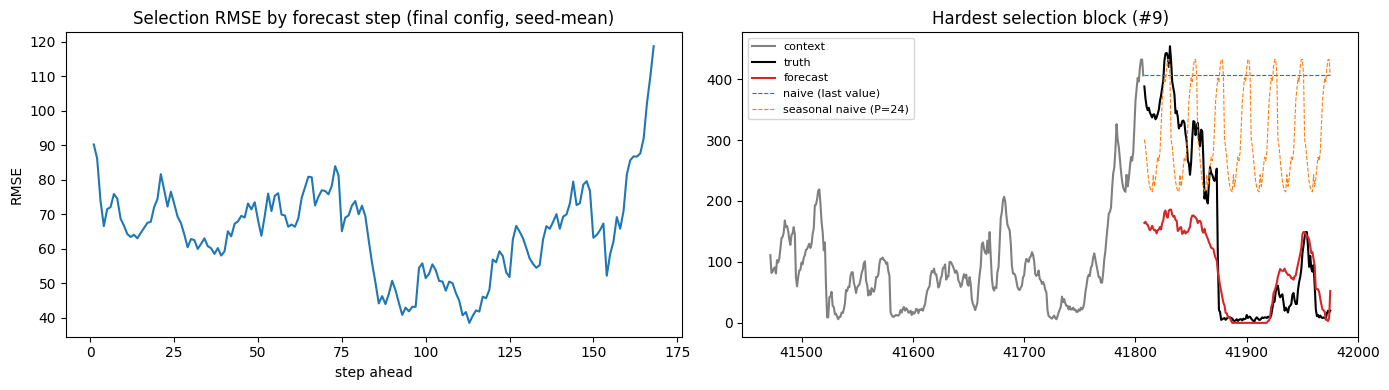

In [19]:
# ── Where the metrics disagree (§2.6) and how error grows with the horizon ───────────────
final_runs = [run({k: v for k, v in FINAL_CFG.items() if BASE.get(k) != v}, s) for s in SEEDS]
pred_mean = np.mean([r["pred"] for r in final_runs], axis=0)
step_rmse = np.sqrt(((pred_mean - TRUTH) ** 2).mean(axis=0))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(np.arange(1, HORIZON + 1), step_rmse)
axes[0].set(title="Selection RMSE by forecast step (final config, seed-mean)",
            xlabel="step ahead", ylabel="RMSE")
worst = int(np.argmax(block_rmse(pred_mean)))
o = SEL_ORIGINS[worst]
axes[1].plot(np.arange(o - 336, o), y_raw[o - 336:o], color="gray", label="context")
axes[1].plot(np.arange(o, o + HORIZON), TRUTH[worst], color="k", label="truth")
axes[1].plot(np.arange(o, o + HORIZON), pred_mean[worst], color="C3", label="forecast")
for name in ("naive (last value)", f"seasonal naive (P={SHORT_PERIOD})"):
    axes[1].plot(np.arange(o, o + HORIZON), baselines[name][worst], lw=0.8, ls="--", label=name)
axes[1].set(title=f"Hardest selection block (#{worst})")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "horizon_and_hardest_block.pdf")
plt.show()

## 9.4 v2: what the leaderboard actually rewards

Attempt 1 (v1, `d_model=16`, early-stop, one seed) scored **RMSE 83.24, rank 12**.
Regressing `Score − RMSE` on (P, E) over the public leaderboard rows fits every row to the
4th decimal:

**Score ≈ RMSE + 1.9·10⁻⁹·P + 5.0·10⁻⁴·E**

So 1M parameters cost +0.002 and 100 epochs +0.05. Against RMSE gaps of 5–20 between
ranks, **the ranking is decided by RMSE on the single hidden 168-step block**, and the size
preference used in v1 doesn't pay off.

v2 therefore targets RMSE. Every change is tested on the same 20 selection blocks × 3 seeds
before it's used:

1. better use of the optional file (the only thing that clearly helped in v1):
   engineered covariates, a non-linear mark embedding, and a direct covariate head;
2. a training schedule that doesn't kill the learning rate after a few epochs (cosine);
3. capacity and context length, re-tested now that P and E are nearly free;
4. a **seed ensemble** (averaging lowers variance; one 168-step block is very noisy);
5. **refitting on the most recent data**: v1's final model never trained on the last
   3,360 steps. This is back-tested in the same chronological way before it's used.

In [20]:
# ── Leaderboard penalty, estimated from the public leaderboard rows (RMSE, P, E, Score) ──
lb = pd.DataFrame([(62.9497, 53_670, 20, 62.9599), (69.1586, 7_938, 5, 69.1612),
                   (69.8003, 365_187, 24, 69.8130), (73.9137, 38_890, 40, 73.9338),
                   (74.6528, 491_528, 233, 74.7703), (76.2469, 79_695, 15, 76.2546),
                   (77.7383, 106_100, 75, 77.7761), (78.3089, 142_410, 40, 78.3292),
                   (81.1122, 446_085, 105, 81.1656), (83.2421, 7_969, 5, 83.2447)],
                  columns=["RMSE", "P", "E", "Score"])
(alpha, beta), *_ = np.linalg.lstsq(lb[["P", "E"]].to_numpy(float),
                                    (lb.Score - lb.RMSE).to_numpy(), rcond=None)
lb["fitted penalty"] = alpha * lb.P + beta * lb.E
lb["Score - RMSE"] = lb.Score - lb.RMSE
display(lb.round(4))
print(f"alpha ≈ {alpha:.2e} per parameter, beta ≈ {beta:.2e} per epoch")
print(f"e.g. a 5-model ensemble of 30k-parameter models x 15 epochs adds "
      f"{alpha * 150_000 + beta * 75:.4f} to the score")

,RMSE,P,E,Score,fitted penalty,Score - RMSE
0,62.9497,53670,20,62.9599,0.0101,0.0102
1,69.1586,7938,5,69.1612,0.0025,0.0026
2,69.8003,365187,24,69.8130,0.0127,0.0127
3,73.9137,38890,40,73.9338,0.0201,0.0201
4,74.6528,491528,233,74.7703,0.1175,0.1175
5,76.2469,79695,15,76.2546,0.0077,0.0077
6,77.7383,106100,75,77.7761,0.0377,0.0378
7,78.3089,142410,40,78.3292,0.0203,0.0203
8,81.1122,446085,105,81.1656,0.0534,0.0534
9,83.2421,7969,5,83.2447,0.0025,0.0026


alpha ≈ 1.89e-09 per parameter, beta ≈ 5.00e-04 per epoch
e.g. a 5-model ensemble of 30k-parameter models x 15 epochs adds 0.0378 to the score


### 9.4.1 Ablation of the v2 changes (optional file used past + future)
Rows add one change at a time. The covariate head is tested both with and without the MLP mark embedding, and the cosine schedule is added on top of the better of the two, so each change is measured on its own.

In [21]:
V1_BEST = dict(transform="none", phase=False, external="future", d_model=16, d_ff=32)
EXP4 = {
    "v1 best": dict(V1_BEST),
    "+ engineered covariates": dict(V1_BEST, features="engineered"),
    "+ MLP mark embedding": dict(V1_BEST, features="engineered", mark_mlp=True),
    "+ covariate head": dict(V1_BEST, features="engineered", mark_mlp=True, exo_head=True),
    # same head WITHOUT the MLP marks, so a harmful MLP can't hide behind the cumulative chain
    "+ covariate head, linear marks": dict(V1_BEST, features="engineered", exo_head=True),
}
exp4a, res4a = experiment("exp4a_v2_covariates", EXP4)
labels = list(EXP4)
for previous, current in zip(labels[:4], labels[1:4]):
    paired(res4a, current, previous)
paired(res4a, "+ covariate head, linear marks", "+ engineered covariates")
paired(res4a, "+ covariate head, linear marks", "+ covariate head")

# The schedule change is tested on top of the better of the two covariate-head variants.
head_best = min(["+ covariate head", "+ covariate head, linear marks"],
                key=lambda k: exp4a.set_index("variant").loc[k, "RMSE mean"])
EXP4["+ cosine schedule (15 ep)"] = dict(EXP4[head_best], schedule="cosine", max_epochs=15,
                                         patience=5)
exp4b, res4b = experiment("exp4b_v2_schedule", {
    head_best: EXP4[head_best], "+ cosine schedule (15 ep)": EXP4["+ cosine schedule (15 ep)"]})
paired(res4b, "+ cosine schedule (15 ep)", head_best)

exp4 = pd.concat([exp4a, exp4b]).drop_duplicates("variant").reset_index(drop=True)
res4 = {**res4a, **res4b}
exp4.to_csv(OUT / "exp4_v2_cumulative.csv", index=False)
best4 = exp4.sort_values("RMSE mean").iloc[0].variant
print("best v2 feature/architecture setting:", best4)

▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 16, 'd_ff': 32, 'features': 'engineered'} seed=0
   RMSE 73.41  MAE 56.28  sMAPE 73.9  P=8,417  E=7 (best epoch 4, 66s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 16, 'd_ff': 32, 'features': 'engineered'} seed=1
   RMSE 65.12  MAE 48.63  sMAPE 70.0  P=8,417  E=4 (best epoch 1, 38s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 16, 'd_ff': 32, 'features': 'engineered'} seed=2
   RMSE 67.73  MAE 49.92  sMAPE 68.7  P=8,417  E=4 (best epoch 1, 38s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 16, 'd_ff': 32, 'features': 'engineered', 'mark_mlp': True} seed=0
   RMSE 64.25  MAE 49.00  sMAPE 69.1  P=8,993  E=10 (best epoch 10, 95s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 16, 'd_ff': 32, 'features': 'engineered', 'mark_mlp': True} seed=1
   RMSE 58.80  MAE 43.50  sMAPE 68.4  P=8,993  E=6 (best epoch 3, 57

,variant,RMSE mean,RMSE std,MAE mean,MAE std,sMAPE mean,sMAPE std,P,E mean
0,v1 best,69.568,0.651,51.645,0.214,72.004,1.033,7969,7.000
1,+ engineered covariates,68.753,4.243,51.609,4.094,70.882,2.719,8417,5.000
2,+ MLP mark embedding,61.512,2.729,46.067,2.768,67.678,1.845,8993,8.667
3,+ covariate head,60.388,4.121,44.559,3.177,66.646,1.406,15970,6.000
4,"+ covariate head, linear marks",60.939,2.461,46.505,2.389,67.192,1.234,15394,6.000


+ engineered covariates vs v1 best: mean block-RMSE diff -0.70 (95% CI -4.09..+2.59), + engineered covariates wins 55% of blocks
+ MLP mark embedding vs + engineered covariates: mean block-RMSE diff -6.91 (95% CI -11.65..-1.52), + MLP mark embedding wins 75% of blocks
+ covariate head vs + MLP mark embedding: mean block-RMSE diff -1.12 (95% CI -3.83..+1.64), + covariate head wins 65% of blocks
+ covariate head, linear marks vs + engineered covariates: mean block-RMSE diff -6.79 (95% CI -12.42..-0.24), + covariate head, linear marks wins 70% of blocks
+ covariate head, linear marks vs + covariate head: mean block-RMSE diff +1.24 (95% CI -1.44..+3.80), + covariate head, linear marks wins 35% of blocks
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 16, 'd_ff': 32, 'features': 'engineered', 'mark_mlp': True, 'exo_head': True, 'schedule': 'cosine', 'max_epochs': 15, 'patience': 5} seed=0
   RMSE 60.58  MAE 45.67  sMAPE 69.5  P=15,970  E=11 (best epoch 6, 107s)
▶ {'

,variant,RMSE mean,RMSE std,MAE mean,MAE std,sMAPE mean,sMAPE std,P,E mean
0,+ covariate head,60.388,4.121,44.559,3.177,66.646,1.406,15970,6.0
1,+ cosine schedule (15 ep),61.274,3.571,45.538,2.668,67.009,2.174,15970,8.0


+ cosine schedule (15 ep) vs + covariate head: mean block-RMSE diff +1.00 (95% CI -0.38..+2.47), + cosine schedule (15 ep) wins 40% of blocks
best v2 feature/architecture setting: + covariate head


### 9.5 Capacity and context length (P and E are nearly free on the leaderboard)

In [22]:
BEST4 = EXP4[best4]
EXP5 = {
    "best4 (d_model=16)": dict(BEST4),
    "d_model=32": dict(BEST4, d_model=32, d_ff=64),
    "d_model=64": dict(BEST4, d_model=64, d_ff=128),
    "seq_len=168": dict(BEST4, seq_len=168, label_len=96),
}
exp5, res5 = experiment("exp5_v2_capacity_context", EXP5)
for label in list(EXP5)[1:]:
    paired(res5, label, "best4 (d_model=16)")
best5 = exp5.sort_values("RMSE mean").iloc[0].variant
print("best v2 configuration:", best5)

▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 32, 'd_ff': 64, 'features': 'engineered', 'mark_mlp': True, 'exo_head': True} seed=0
   RMSE 59.01  MAE 43.98  sMAPE 70.4  P=47,298  E=4 (best epoch 1, 100s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 32, 'd_ff': 64, 'features': 'engineered', 'mark_mlp': True, 'exo_head': True} seed=1
   RMSE 58.51  MAE 44.07  sMAPE 68.7  P=47,298  E=5 (best epoch 2, 120s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 32, 'd_ff': 64, 'features': 'engineered', 'mark_mlp': True, 'exo_head': True} seed=2
   RMSE 58.04  MAE 43.90  sMAPE 68.2  P=47,298  E=4 (best epoch 1, 96s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 64, 'd_ff': 128, 'features': 'engineered', 'mark_mlp': True, 'exo_head': True} seed=0
   RMSE 57.80  MAE 43.52  sMAPE 71.6  P=156,034  E=8 (best epoch 5, 430s)
▶ {'transform': 'none', 'phase': False, 'external': 'future', 'd_model': 64

,variant,RMSE mean,RMSE std,MAE mean,MAE std,sMAPE mean,sMAPE std,P,E mean
0,best4 (d_model=16),60.388,4.121,44.559,3.177,66.646,1.406,15970,6.000
1,d_model=32,58.520,0.488,43.983,0.083,69.080,1.183,47298,4.333
2,d_model=64,59.425,3.260,43.831,2.084,71.945,4.197,156034,5.667
3,seq_len=168,56.765,2.094,43.095,2.158,69.802,3.647,15970,6.000


d_model=32 vs best4 (d_model=16): mean block-RMSE diff -0.73 (95% CI -4.35..+2.37), d_model=32 wins 40% of blocks
d_model=64 vs best4 (d_model=16): mean block-RMSE diff -0.37 (95% CI -3.89..+3.33), d_model=64 wins 65% of blocks
seq_len=168 vs best4 (d_model=16): mean block-RMSE diff -2.14 (95% CI -7.38..+3.02), seq_len=168 wins 50% of blocks
best v2 configuration: seq_len=168


### 9.6 Seed ensemble and refit, both back-tested on the selection blocks

* **Ensemble**: average the forecasts of the 3 seeds already trained. No new training.
* **Refit back-test**: reproduce the final procedure one step earlier in time.
  Early-stop on the early-stop region (as above), then retrain on train + early-stop data
  for the same number of epochs, and score on the selection blocks. If this beats the
  early-stopped model, the final model is refitted on the full history in the same way
  (§2.7: E counts both phases).

In [23]:
def ensemble_metrics(runs):
    return metrics(TRUTH, np.mean([r["pred"] for r in runs], axis=0))


ens_rows = []
for label, runs in {**res4, **res5}.items():
    ens_rows.append({"variant": label,
                     "single model RMSE (seed mean)": np.mean([r["RMSE"] for r in runs]),
                     "3-seed ensemble RMSE": ensemble_metrics(runs)["RMSE"],
                     "3-seed ensemble MAE": ensemble_metrics(runs)["MAE"],
                     "3-seed ensemble sMAPE": ensemble_metrics(runs)["sMAPE"]})
ens_table = pd.DataFrame(ens_rows).drop_duplicates("variant")
ens_table.to_csv(OUT / "exp6_seed_ensemble.csv", index=False)
display(ens_table.round(3))

V2_OVR = EXP5[best5]
refit_rows, refit_preds = [], []
for seed in SEEDS:
    base = run(V2_OVR, seed)                       # < TRAIN_END, early-stopped on ES region
    cfg = {**BASE, **V2_OVR}
    refit_cfg = {**cfg, "max_epochs": base["best_epoch"], "patience": 10 ** 9,
                 "sched_epochs": cfg.get("sched_epochs") or cfg["max_epochs"]}
    model, D, info = train_model(refit_cfg, seed, SEL_START, SEL_START, verbose=False)
    pred = evaluate_selection(model, D, refit_cfg)
    refit_preds.append(pred)
    refit_rows.append({"seed": seed, "early-stop RMSE": base["RMSE"],
                       "refit RMSE": metrics(TRUTH, pred)["RMSE"],
                       "block diff (refit - early-stop)": block_rmse(pred) - base["block_rmse"]})
    del model
    torch.cuda.empty_cache()
refit_table = pd.DataFrame(refit_rows)
diff = np.mean(np.stack(refit_table["block diff (refit - early-stop)"]), axis=0)
boot = np.random.default_rng(0).choice(diff, (5000, len(diff))).mean(axis=1)
lo, hi = np.percentile(boot, [2.5, 97.5])
refit_table.drop(columns="block diff (refit - early-stop)").to_csv(OUT / "exp7_refit_backtest.csv",
                                                                   index=False)
display(refit_table.drop(columns="block diff (refit - early-stop)").round(3))
ens_refit = metrics(TRUTH, np.mean(refit_preds, axis=0))["RMSE"]
print(f"refit - early-stop: mean block-RMSE diff {diff.mean():+.2f} (95% CI {lo:+.2f}..{hi:+.2f}),"
      f" refit wins {np.mean(diff < 0):.0%} of blocks; refit 3-seed ensemble RMSE {ens_refit:.2f}")

# ── v2 decisions (validation evidence only) ─────────────────────────────────────────────
row = ens_table.set_index("variant").loc[best5]
V2_FINAL_SEEDS = [0, 1, 2, 3, 4] if row["3-seed ensemble RMSE"] < row["single model RMSE (seed mean)"] else [0]
V2_FINAL_MODE = "refit" if diff.mean() < 0 else "early_stop"
FINAL_CFG = {**BASE, **V2_OVR}
final_runs = res5[best5]                           # used by the output-floor check below
print("final configuration:", best5, "| mode:", V2_FINAL_MODE, "| seeds:", V2_FINAL_SEEDS)
print(json.dumps(FINAL_CFG, indent=1))

,variant,single model RMSE (seed mean),3-seed ensemble RMSE,3-seed ensemble MAE,3-seed ensemble sMAPE
0,v1 best,69.568,66.479,49.131,64.918
1,+ engineered covariates,68.753,66.130,49.522,66.302
2,+ MLP mark embedding,61.512,57.941,43.271,59.806
3,+ covariate head,60.388,57.399,41.872,58.934
4,"+ covariate head, linear marks",60.939,58.450,44.379,60.614
5,+ cosine schedule (15 ep),61.274,57.618,42.476,59.626
6,best4 (d_model=16),60.388,57.399,41.872,58.934
7,d_model=32,58.520,55.020,41.168,60.428
8,d_model=64,59.425,54.894,40.066,59.616
9,seq_len=168,56.765,54.572,41.231,61.619


,seed,early-stop RMSE,refit RMSE
0,0,55.268,53.674
1,1,59.158,61.629
2,2,55.869,55.943


refit - early-stop: mean block-RMSE diff +0.11 (95% CI -1.81..+1.83), refit wins 45% of blocks; refit 3-seed ensemble RMSE 54.59
final configuration: seq_len=168 | mode: early_stop | seeds: [0, 1, 2, 3, 4]
{
 "seq_len": 168,
 "label_len": 96,
 "pred_len": 168,
 "transform": "none",
 "phase": false,
 "external": "future",
 "d_model": 16,
 "n_heads": 4,
 "e_layers": 2,
 "d_layers": 1,
 "d_ff": 32,
 "moving_avg": 25,
 "factor": 3,
 "dropout": 0.05,
 "lr": 0.001,
 "weight_decay": 0.0001,
 "batch_size": 128,
 "max_epochs": 10,
 "patience": 3,
 "train_stride": 1,
 "features": "engineered",
 "mark_mlp": true,
 "exo_head": true,
 "schedule": "halve",
 "sched_epochs": null
}


## 10. Final model and leaderboard submission

`FINAL_MODE` controls what produces the submitted forecast. Both obey §2.7's counting rules:

* `"early_stop"` (default, cheapest): train once on targets `< SEL_START` and early-stop on
  the 20 most recent blocks. **E = epochs run**.
* `"refit"`: additionally retrain on the whole history for `best_epoch` epochs.
  **E = early-stop epochs + refit epochs** ("count both").

`FINAL_SEEDS` with more than one seed builds an ensemble; P and E are summed over the members.
Forecasts are produced in one shot from the end of the history, for
`time_idx = 43,657 … 43,824`, in chronological order.

In [24]:
FINAL_MODE = V2_FINAL_MODE    # decided by the refit back-test in §9.6
FINAL_SEEDS = V2_FINAL_SEEDS  # seed ensemble decided in §9.6 (P and E summed over members)

members, P_total, E_total = [], 0, 0
for seed in FINAL_SEEDS:
    print(f"final model, seed {seed}")
    model, D, info = train_model(FINAL_CFG, seed, SEL_START, N_TRAIN)
    E_seed = info["E"]
    if FINAL_MODE == "refit":
        refit_cfg = {**FINAL_CFG, "max_epochs": info["best_epoch"], "patience": 10 ** 9,
                     "sched_epochs": FINAL_CFG.get("sched_epochs") or FINAL_CFG["max_epochs"]}
        # Train on the whole history for a FIXED number of epochs (= best early-stop epoch):
        # there is no held-out data left to early-stop on.
        model, D, refit_info = train_model(refit_cfg, seed, N_TRAIN, N_TRAIN)
        E_seed += refit_info["E"]
    origin = torch.as_tensor([N_TRAIN], device=DEVICE)    # first hidden position (43,657)
    z = predict(model, origin, D).cpu().numpy()
    members.append(inverse_transform(z, D["stats"], FINAL_CFG)[0])
    P_total += info["P"]
    E_total += E_seed

forecast = np.mean(members, axis=0)
assert forecast.shape == (HORIZON,) and np.isfinite(forecast).all() and (forecast >= 0).all()
print(f"P (trainable parameters, summed over {len(FINAL_SEEDS)} model(s)) = {P_total:,}")
print(f"E (training epochs used to produce these forecasts)            = {E_total}")

final model, seed 0
  epoch  1 train 0.6582 early-stop 0.4734 (8s)
  epoch  2 train 0.4991 early-stop 0.4583 (15s)
  epoch  3 train 0.4655 early-stop 0.4521 (23s)
  epoch  4 train 0.4512 early-stop 0.4469 (31s)
  epoch  5 train 0.4446 early-stop 0.4485 (38s)
  epoch  6 train 0.4405 early-stop 0.4479 (46s)
  epoch  7 train 0.4397 early-stop 0.4482 (53s)
final model, seed 1
  epoch  1 train 0.6651 early-stop 0.4929 (8s)
  epoch  2 train 0.4900 early-stop 0.5154 (15s)
  epoch  3 train 0.4557 early-stop 0.5077 (23s)
  epoch  4 train 0.4406 early-stop 0.5254 (31s)
final model, seed 2
  epoch  1 train 0.6733 early-stop 0.5300 (8s)
  epoch  2 train 0.5004 early-stop 0.4842 (15s)
  epoch  3 train 0.4602 early-stop 0.4700 (23s)
  epoch  4 train 0.4457 early-stop 0.4676 (31s)
  epoch  5 train 0.4397 early-stop 0.4677 (38s)
  epoch  6 train 0.4362 early-stop 0.4635 (46s)
  epoch  7 train 0.4348 early-stop 0.4633 (53s)
  epoch  8 train 0.4344 early-stop 0.4621 (61s)
  epoch  9 train 0.4340 early-s

In [25]:
# ── Output floor, chosen on the selection blocks only (no retraining: P and E unchanged) ──
# Clipping at 0 turns any negative raw-scale output into an exact 0, but the target is
# almost never 0 (2 of 43,656 values; 0.5 % quantile = 5). Compare floors at low
# TRAINING-region quantiles on the 20 selection blocks x seeds, keep the best by RMSE.
floor_rows = []
for q in (0.0, 0.005, 0.01, 0.02, 0.05):
    floor = float(np.quantile(y_raw[:TRAIN_END], q))
    scores = [metrics(TRUTH, np.maximum(r["pred"], floor)) for r in final_runs]
    floor_rows.append({"train quantile": q, "floor": floor,
                       **{m: np.mean([s[m] for s in scores]) for m in ("RMSE", "MAE", "sMAPE")}})
floor_table = pd.DataFrame(floor_rows)
floor_table.to_csv(OUT / "floor_check.csv", index=False)
display(floor_table.round(3))
FLOOR = float(floor_table.sort_values("RMSE").iloc[0]["floor"])
FINAL_CFG["output_floor"] = FLOOR           # recorded in submission_record.json
forecast = np.maximum(forecast, FLOOR)
print(f"floor = {FLOOR:g}; zeros left in forecast: {int((forecast == 0).sum())}")

,train quantile,floor,RMSE,MAE,sMAPE
0,0.000,0.0,56.765,43.095,69.802
1,0.005,5.0,56.656,42.643,59.035
2,0.010,7.0,56.618,42.477,56.884
3,0.020,8.0,56.600,42.409,56.156
4,0.050,11.0,56.557,42.281,55.028


floor = 11; zeros left in forecast: 0


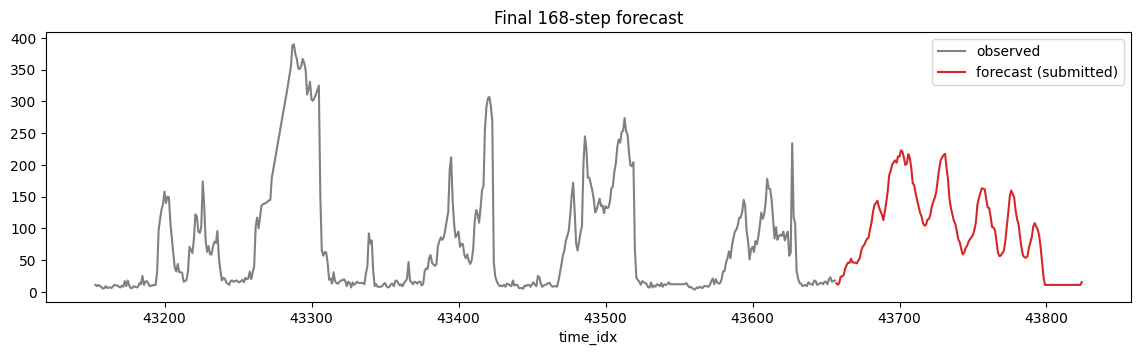

Declare on the leaderboard:  P = 79850  E = 36

Paste this (168 values, chronological):

13.7006, 11.2548, 13.8430, 23.7466, 24.6664, 26.2943, 36.6175, 42.0872, 46.1871, 45.5719, 52.1411, 46.4599, 45.9694, 46.1487, 44.8433, 49.5696, 53.5092, 65.0092, 71.4049, 73.9620, 79.6954, 83.5870, 85.4233, 98.6778, 109.9019, 125.9109, 137.2876, 140.1223, 143.6316, 133.8582, 127.5242, 122.1449, 113.0080, 125.6207, 141.3826, 158.6044, 184.0841, 190.4544, 200.3037, 204.0693, 207.1571, 203.5894, 213.4599, 213.0055, 223.0262, 220.7333, 211.4599, 199.9013, 201.7178, 216.9496, 211.1918, 195.2807, 171.3211, 168.1238, 154.8383, 144.4168, 133.9666, 124.3714, 119.1278, 108.1872, 104.3371, 105.4670, 113.8316, 114.8095, 121.3970, 134.6282, 141.9907, 148.0856, 157.9168, 175.5979, 194.0916, 207.1062, 211.8159, 215.4244, 217.5244, 195.5454, 177.6294, 146.2587, 131.8505, 121.9763, 111.8339, 106.9567, 95.2959, 82.6821, 78.1587, 67.8925, 59.0658, 61.7219, 69.1523, 72.6149, 79.3991, 82.7241, 86.2409, 89.8908, 98.0930

In [26]:
# ── Paste-ready submission + reproducibility record ──────────────────────────────────────
submission = pd.DataFrame({"time_idx": np.arange(43_657, 43_825), "value": forecast})
submission.to_csv(OUT / "forecast_168.csv", index=False)
paste = ", ".join(f"{v:.4f}" for v in forecast)          # v1 (43,657) ... v168 (43,824)
(OUT / "leaderboard_paste.txt").write_text(paste)
record = dict(final_config=FINAL_CFG, final_mode=FINAL_MODE, final_seeds=FINAL_SEEDS,
              P=int(P_total), E=int(E_total), periods=PERIODS,
              selection_RMSE_mean_over_seeds=float(np.mean([r["RMSE"] for r in final_runs])))
(OUT / "submission_record.json").write_text(json.dumps(record, indent=1))

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(np.arange(N_TRAIN - 3 * 168, N_TRAIN) + 1, y_raw[-3 * 168:], color="gray",
        label="observed")
ax.plot(submission.time_idx, forecast, color="C3", label="forecast (submitted)")
ax.set(xlabel="time_idx", title="Final 168-step forecast")
ax.legend()
plt.savefig(OUT / "final_forecast.pdf", bbox_inches="tight")
plt.show()
print("Declare on the leaderboard:  P =", P_total, " E =", E_total)
print("\nPaste this (168 values, chronological):\n")
print(paste)

### Leaderboard log (at most 5 submissions; last one counts)

Treat each submission as **confirmation**, not tuning. A single 168-step block is one
sample, while the selection estimate averages 20 blocks × several seeds.

| # | config / seeds | P | E | selection RMSE | leaderboard score |
|---|---|---|---|---|---|
| 1 | | | | | |